# 01 · Análisis exploratorio (Sección 4.1)

Responsable: **Lucía Mora**.

Antes de ejecutar este notebook hay que haber lanzado `python scripts/build_dataset.py`.

Las figuras se guardan en `figures/eda_*.png` y las tablas en `results/eda_*.csv` para poder
citarlas en el README.

**Criterio:** las secciones 1–3 describen el conjunto completo. El análisis de texto (sección 4)
se hace **solo con la partición de entrenamiento**, para no tomar ninguna decisión mirando test.

In [1]:
import sys, json, re
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cordis import config
from cordis.data import load_projects, load_dataset, load_taxonomy, code_names

FIG = config.FIGURES_DIR; FIG.mkdir(exist_ok=True)
RES = config.RESULTS_DIR; RES.mkdir(exist_ok=True)

# Estilo común: ejes y rejilla discretos, marcas finas
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b0b0a8", "axes.labelcolor": "#3a3a36", "xtick.color": "#5c5c56",
    "ytick.color": "#5c5c56", "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})
BLUE = "#2a78d6"
# Un color fijo por raíz (nivel 1); se usa en todas las figuras para que cada área se reconozca
ROOT_COLORS = {23: "#2a78d6", 25: "#eb6834", 29: "#1baf7a", 21: "#eda100", 31: "#e87ba4", 27: "#008300"}

def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show()

raw = load_projects()
df = load_dataset()
names = code_names(load_taxonomy())
print(f"Proyectos originales: {len(raw):,} · con etiqueta válida: {len(df):,}")

Proyectos originales: 35,378 · con etiqueta válida: 31,951


## 1. Descripción general

In [2]:
desc = pd.DataFrame({
    "tipo": raw.drop(columns="codes").dtypes.astype(str),
    "ausentes": raw.drop(columns="codes").isna().sum(),
})
desc["% ausentes"] = (100 * desc["ausentes"] / len(raw)).round(1)
desc["ejemplo"] = [str(raw[c].dropna().iloc[0])[:50] if raw[c].notna().any() else "" for c in desc.index]
desc.to_csv(RES / "eda_variables.csv")
print(f"{raw.shape[0]:,} filas × {raw.shape[1]-1} columnas")
desc

35,378 filas × 19 columnas


,tipo,ausentes,% ausentes,ejemplo
projectID,int64,0,0.0,115843
acronym,object,0,0.0,EbolaMoDRAD
title,object,0,0.0,Ebola Virus: Modern Approaches for developing ...
summary,object,0,0.0,The current Ebola Virus Disease (EVD) outbreak...
startDate,datetime64[ns],11,0.0,2015-02-01 00:00:00
endDate,datetime64[ns],11,0.0,2018-01-31 00:00:00
totalCost,float64,0,0.0,4300935.0
ecMaxContribution,float64,0,0.0,4300935.0
masterCall,object,20358,57.5,H2020-JTI-IMI2-2014-02-single-stage
subCall,object,0,0.0,H2020-JTI-IMI2-2014-02-single-stage


**Observaciones.**
- `euroSciVocCode` falta en 3.326 proyectos (9,4 %), que no pueden etiquetarse.
- `patentID` está vacío en el 97,5 % y `publicationID` en el 51 %; solo interesan para la extensión de producción científica.
- `masterCall` está vacío en el 58 %.
- Las columnas `topic` y `topic_title` describen la convocatoria y están muy ligadas a la temática. **No se usan como entrada** (ver `docs/decisiones.md`, D4).

## 2. Variable objetivo

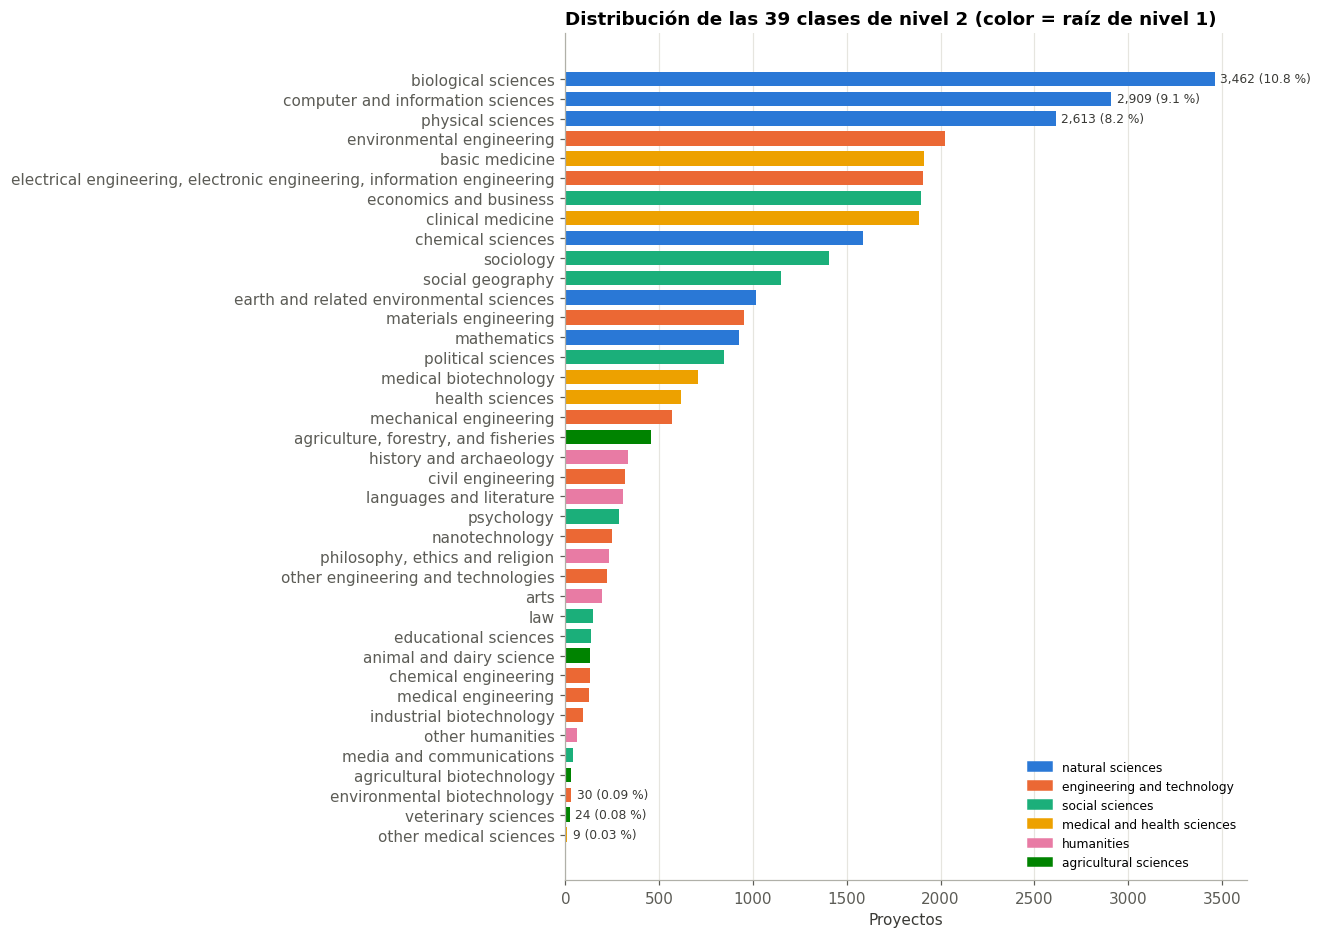

Clases: 39 · mayor: 3462 · menor: 9 · ratio de desbalance 385:1
Las 5 clases mayores suman el 40.4 % de los proyectos; 7 clases tienen < 100 proyectos


In [3]:
cnt = df.groupby(["label_l2", "label_l1"]).size().rename("n").reset_index()
cnt["name"] = cnt["label_l2"].map(names)
cnt = cnt.sort_values("n")
cnt["pct"] = 100 * cnt["n"] / cnt["n"].sum()

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(cnt["name"], cnt["n"], color=cnt["label_l1"].map(ROOT_COLORS), height=0.72)
ax.set_xlabel("Proyectos"); ax.grid(axis="y", visible=False)
ax.set_title("Distribución de las 39 clases de nivel 2 (color = raíz de nivel 1)", loc="left")
for y, (n, p) in enumerate(zip(cnt["n"], cnt["pct"])):
    if y >= len(cnt) - 3 or y < 3:   # etiqueta solo los extremos
        ax.text(n + 30, y, f"{n:,} ({p:.2f} %)" if p < 1 else f"{n:,} ({p:.1f} %)", va="center", fontsize=8, color="#3a3a36")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ROOT_COLORS.values()]
ax.legend(handles, [names[r] for r in ROOT_COLORS], frameon=False, loc="lower right", fontsize=8)
save(fig, "eda_class_distribution_l2")

imb = cnt["n"].max() / cnt["n"].min()
top5 = cnt.nlargest(5, "n")["pct"].sum()
print(f"Clases: {len(cnt)} · mayor: {cnt['n'].max()} · menor: {cnt['n'].min()} · ratio de desbalance {imb:.0f}:1")
print(f"Las 5 clases mayores suman el {top5:.1f} % de los proyectos; {(cnt['n'] < 100).sum()} clases tienen < 100 proyectos")

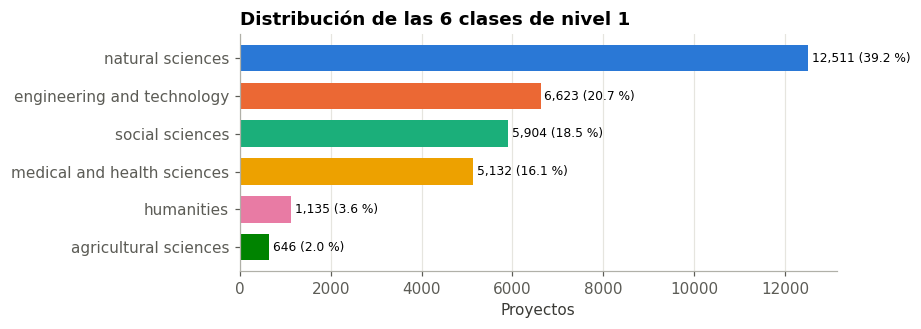

In [4]:
c1 = df["label_l1"].value_counts()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh([names[i] for i in c1.index[::-1]], c1.values[::-1],
        color=[ROOT_COLORS[i] for i in c1.index[::-1]], height=0.7)
for y, n in enumerate(c1.values[::-1]):
    ax.text(n + 80, y, f"{n:,} ({100*n/len(df):.1f} %)", va="center", fontsize=8)
ax.set_xlabel("Proyectos"); ax.grid(axis="y", visible=False)
ax.set_title("Distribución de las 6 clases de nivel 1", loc="left")
save(fig, "eda_class_distribution_l1")

In [5]:
checks = json.load(open(RES / "week1_checks.json", encoding="utf-8"))
base = pd.DataFrame({
    lvl: {"clase mayoritaria": checks[f"baseline_l{n}_test"]["majority_class"].split(" - ")[1],
          "accuracy (test)": checks[f"baseline_l{n}_test"]["accuracy"],
          "macro-F1 (test)": checks[f"baseline_l{n}_test"]["macro_f1"]}
    for lvl, n in (("nivel 2", 2), ("nivel 1", 1))}).T
base.to_csv(RES / "eda_baseline.csv"); base

,clase mayoritaria,accuracy (test),macro-F1 (test)
nivel 2,biological sciences,0.1083,0.005
nivel 1,natural sciences,0.3914,0.0938


### 2.1. Ambigüedad de la etiqueta

¿Cuántas áreas distintas tiene cada proyecto? Esto marca el «techo» del que habla el enunciado.

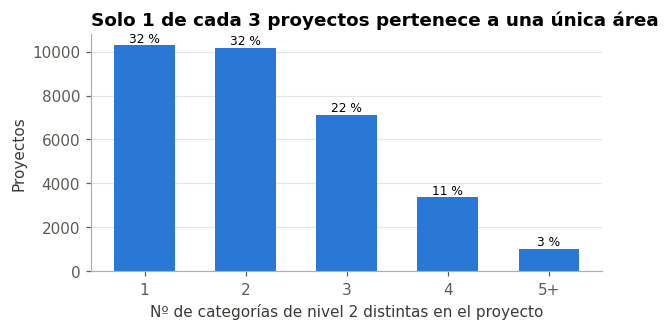

Media de áreas de nivel 2 por proyecto: 2.21


In [6]:
amb = df["n_l2"].clip(upper=5).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.bar([str(i) if i < 5 else "5+" for i in amb.index], amb.values, color=BLUE, width=0.6)
for x, n in enumerate(amb.values):
    ax.text(x, n + 150, f"{100*n/len(df):.0f} %", ha="center", fontsize=8)
ax.set_xlabel("Nº de categorías de nivel 2 distintas en el proyecto"); ax.set_ylabel("Proyectos")
ax.grid(axis="x", visible=False)
ax.set_title("Solo 1 de cada 3 proyectos pertenece a una única área", loc="left")
save(fig, "eda_label_ambiguity")
print(f"Media de áreas de nivel 2 por proyecto: {df['n_l2'].mean():.2f}")

## 3. Estadísticas básicas

count    31951.0
mean       265.3
std         41.9
min          1.0
25%        257.0
50%        276.0
75%        289.0
max        587.0


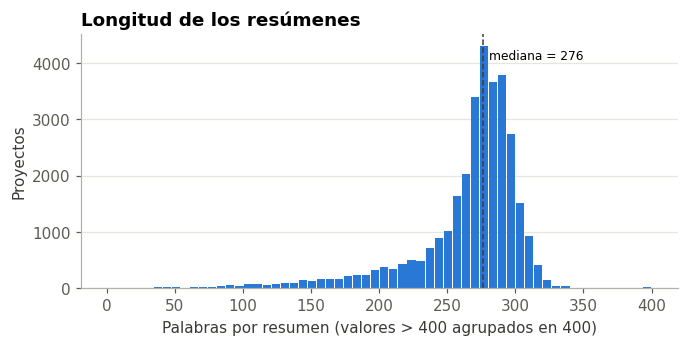


Resúmenes con < 30 palabras: 25


,projectID,title,summary,label_l2_name
98,775987,Innovative Enterprise Malta 2017,Innovative Enterprise / Malta 2017 / 31st May ...,social geography
5803,956745,European Training Network for InduStry Digital...,European Training Network for InduStry Digital...,biological sciences
5843,683913,Feasibility study to determine the use of ITS ...,Safe solid slurry detector is a new instrument...,environmental engineering
8355,726320,Human Puripotent Stem Cell Registry,European registry for human embryonic stem cel...,medical biotechnology
10921,645094,Automatic Sentiment Estimation in the Wild,Automatic Sentiment Estimation in the Wild,mathematics
10925,652527,Production and Market entry financing of Digit...,The DIGISTONE market phase 1 aims at adressing...,arts
12702,643338,NESME Inn,Key account management for Instruments seeking...,economics and business
13524,641110,The Holy Roman Empire of the German Nation and...,The proposed project analyses slavery in the H...,law
14640,945385,Doctorate School in Integrated Genomics Research,Integrated Genomics Research Centre,biological sciences
15487,743407,Business INN Moldova,H2020,political sciences


In [7]:
df["n_words"] = df["summary"].str.split().str.len()
print(df["n_words"].describe().round(1).to_string())
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(df["n_words"].clip(upper=400), bins=60, color=BLUE, rwidth=0.9)
ax.axvline(df["n_words"].median(), color="#3a3a36", lw=1, ls="--")
ax.text(df["n_words"].median() + 5, ax.get_ylim()[1] * 0.9, f"mediana = {df['n_words'].median():.0f}", fontsize=8)
ax.set_xlabel("Palabras por resumen (valores > 400 agrupados en 400)"); ax.set_ylabel("Proyectos")
ax.grid(axis="x", visible=False)
ax.set_title("Longitud de los resúmenes", loc="left")
save(fig, "eda_summary_length")
short = df[df["n_words"] < 30]
print(f"\nResúmenes con < 30 palabras: {len(short)}")
short[["projectID", "title", "summary", "label_l2_name"]].head(10)

In [8]:
n_chars = df["summary"].str.len()
print(n_chars.describe().round(0).to_string())
print(f"\nResúmenes con más de 1.990 caracteres: {100*(n_chars > 1990).mean():.1f} %")

count    31951.0
mean      1838.0
std        278.0
min          5.0
25%       1813.0
50%       1960.0
75%       1991.0
max       3988.0

Resúmenes con más de 1.990 caracteres: 25.3 %


Los resúmenes de CORDIS tienen un **límite de unos 2.000 caracteres**. La mediana es de 1.960
caracteres y alrededor de una cuarta parte está pegada al límite, así que muchos resúmenes pueden
estar **recortados**. Por eso la distribución de palabras cae de golpe en torno a 300. Esto afecta
a los Transformers: casi ningún resumen supera los 512 tokens, por lo que basta con truncar y no
hace falta trocear.

In [9]:
# Longitud en tokens aproximada para los Transformers (~1,3 tokens por palabra en inglés técnico)
over = (df["n_words"] * 1.3 > 512).mean()
print(f"Fracción estimada de resúmenes que superan 512 tokens: {100*over:.1f} % "
      "(dato a comprobar con el tokenizador real en el bloque de Transformers)")

Fracción estimada de resúmenes que superan 512 tokens: 0.1 % (dato a comprobar con el tokenizador real en el bloque de Transformers)


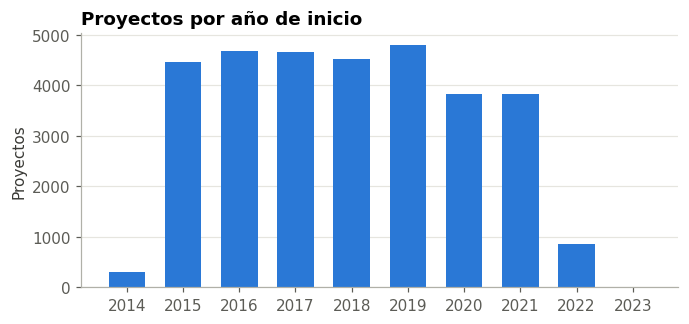

startDate
2014.0     311
2015.0    4472
2016.0    4674
2017.0    4663
2018.0    4531
2019.0    4793
2020.0    3819
2021.0    3827
2022.0     848
2023.0       2


In [10]:
years = df["startDate"].dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(years.index.astype(int).astype(str), years.values, color=BLUE, width=0.65)
ax.set_ylabel("Proyectos"); ax.grid(axis="x", visible=False)
ax.set_title("Proyectos por año de inicio", loc="left")
save(fig, "eda_projects_per_year")
print(years.to_string())

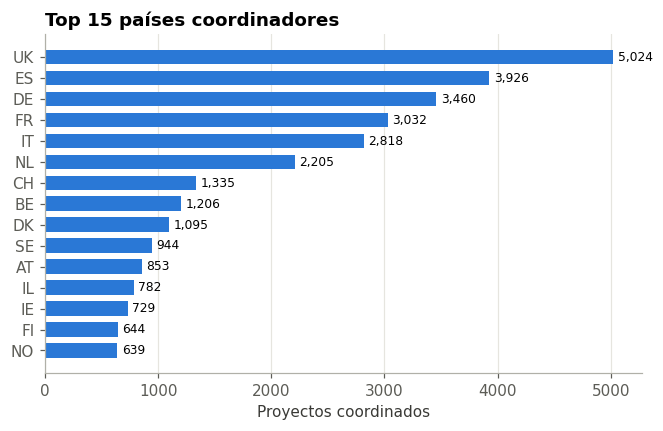

Países coordinadores distintos: 57; los 5 primeros coordinan el 57.2 % de los proyectos


In [11]:
ctry = df["coordinatorCountry"].value_counts()
top = ctry.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
for y, n in enumerate(top.values):
    ax.text(n + 40, y, f"{n:,}", va="center", fontsize=8)
ax.set_xlabel("Proyectos coordinados"); ax.grid(axis="y", visible=False)
ax.set_title("Top 15 países coordinadores", loc="left")
save(fig, "eda_projects_per_country")
print(f"Países coordinadores distintos: {ctry.size}; los 5 primeros coordinan el "
      f"{100*ctry.head(5).sum()/len(df):.1f} % de los proyectos")

## 4. Análisis preliminar del texto (solo train)

Para el EDA se usa una tokenización sencilla: palabras alfabéticas de 3 o más letras, en minúsculas,
sin las stopwords estándar de inglés de scikit-learn. El preprocesado definitivo (spaCy y
lematización) se hace en `src/cordis/preprocess.py`.

Vocabulario (min_df=5): 21,430 términos


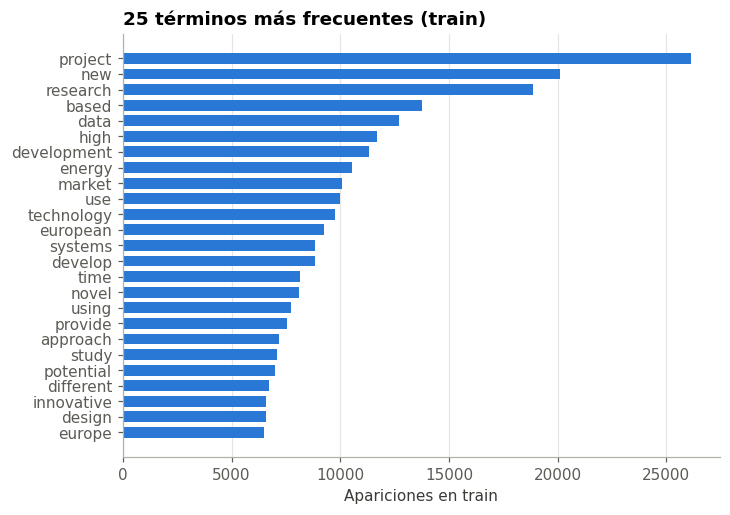

,term,freq,doc_freq
15385,project,26143,0.608334
13082,new,20107,0.505455
16570,research,18861,0.410981
1693,based,13745,0.401547
4689,data,12691,0.250112
8904,high,11692,0.333766
5172,development,11323,0.341232
6435,energy,10526,0.171868
11609,market,10085,0.223598
20631,use,10008,0.318609


In [12]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
tr = df[df["split"] == "train"].reset_index(drop=True)
cv = CountVectorizer(lowercase=True, stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", min_df=5)
Xc = cv.fit_transform(tr["summary"])
vocab = np.array(cv.get_feature_names_out())
freq = np.asarray(Xc.sum(0)).ravel()
docfreq = np.asarray((Xc > 0).sum(0)).ravel() / Xc.shape[0]
top = pd.DataFrame({"term": vocab, "freq": freq, "doc_freq": docfreq}).nlargest(25, "freq")
print(f"Vocabulario (min_df=5): {len(vocab):,} términos")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top["term"][::-1], top["freq"][::-1], color=BLUE, height=0.7)
ax.set_xlabel("Apariciones en train"); ax.grid(axis="y", visible=False)
ax.set_title("25 términos más frecuentes (train)", loc="left")
save(fig, "eda_top_terms")
top.to_csv(RES / "eda_top_terms.csv", index=False)
top

Los términos más frecuentes (*project*, *research*, *new*, *develop*…) son **stopwords del dominio**:
aparecen en casi todos los resúmenes y no distinguen clases. La columna `doc_freq` sugiere qué
`max_df` usar en TF-IDF para eliminarlos.

In [13]:
print("Términos presentes en más del 30 % de los resúmenes de train:")
dd = pd.Series(docfreq, index=vocab).sort_values(ascending=False)
print(dd[dd > 0.3].round(2).to_string())

Términos presentes en más del 30 % de los resúmenes de train:
project        0.61
new            0.51
research       0.41
based          0.40
development    0.34
high           0.33
use            0.32
develop        0.30


In [14]:
cv2 = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
                      ngram_range=(2, 2), min_df=10)
X2 = cv2.fit_transform(tr["summary"])
bg = pd.Series(np.asarray(X2.sum(0)).ravel(), index=cv2.get_feature_names_out()).nlargest(20)
bg.to_frame("freq")

,freq
state art,2730
project aims,1911
long term,1865
real time,1526
large scale,1457
climate change,1319
cutting edge,1120
cost effective,972
low cost,965
develop new,955


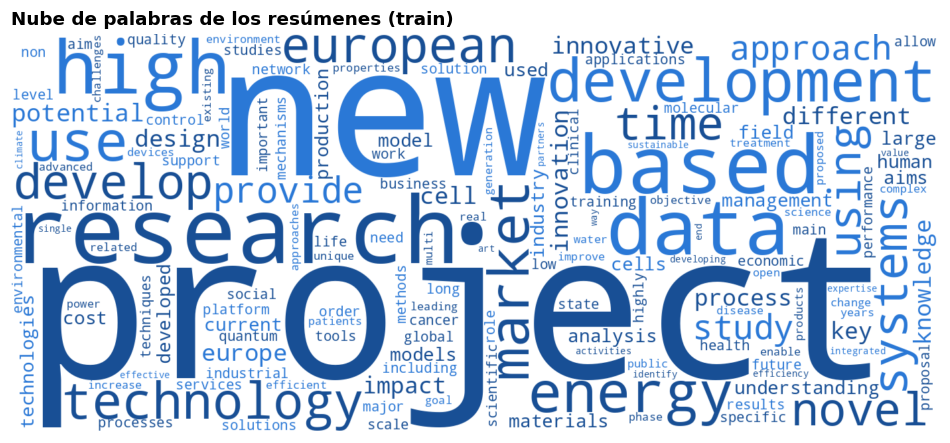

In [15]:
from wordcloud import WordCloud
wc = WordCloud(width=1400, height=600, background_color="white", stopwords=ENGLISH_STOP_WORDS,
               colormap="Blues", max_words=150, random_state=0, collocations=False)
wc.generate_from_frequencies(dict(zip(vocab, freq)))
fig, ax = plt.subplots(figsize=(11, 4.7))
ax.imshow(wc.recolor(color_func=lambda *a, **k: BLUE if np.random.rand() < .5 else "#184f95", random_state=0),
          interpolation="bilinear")
ax.axis("off"); ax.set_title("Nube de palabras de los resúmenes (train)", loc="left")
save(fig, "eda_wordcloud")

### 4.1. Términos característicos por clase

Para cada clase se listan los términos con mayor estadístico χ² frente al resto (calculado en train).
Si estos términos son muy distintos entre clases, una representación de bolsa de palabras ya
debería separarlas bien.

In [16]:
from sklearn.feature_selection import chi2
rows = []
for c in tr["label_l2"].value_counts().index:
    y = (tr["label_l2"] == c).values
    s, _ = chi2(Xc, y)
    # solo términos más frecuentes en la clase que fuera (asociación positiva)
    pos = np.asarray(Xc[y].mean(0)).ravel() > np.asarray(Xc[~y].mean(0)).ravel()
    s = np.where(pos, np.nan_to_num(s), 0)
    rows.append({"clase": names[c], "n_train": int(y.sum()),
                 "términos característicos": ", ".join(vocab[np.argsort(-s)[:8]])})
distinct = pd.DataFrame(rows)
distinct.to_csv(RES / "eda_distinctive_terms.csv", index=False)
pd.set_option("display.max_colwidth", 120)
distinct

,clase,n_train,términos característicos
0,biological sciences,2424,"dna, rna, genome, epigenetic, species, proteins, biology, evolutionary"
1,computer and information sciences,2037,"data, software, learning, security, privacy, cloud, iot, machine"
2,physical sciences,1828,"quantum, physics, matter, dark, spectroscopy, universe, stars, optical"
3,environmental engineering,1415,"energy, renewable, solar, wind, electricity, heat, storage, fuel"
4,basic medicine,1340,"immune, drug, antibiotic, antibiotics, disease, clinical, pharmaceutical, diseases"
5,"electrical engineering, electronic engineering, information engineering",1336,"robotics, wireless, robots, robotic, robot, sensors, sensor, radar"
6,economics and business,1328,"innovation, smes, sme, een, services, productivity, kam, beneficiaries"
7,clinical medicine,1321,"cancer, patients, breast, clinical, treatment, patient, diabetes, surgery"
8,chemical sciences,1110,"catalysis, catalysts, catalytic, oxidation, chemistry, reactions, metal, catalyst"
9,sociology,982,"gender, automation, women, equality, social, migrants, governance, migrant"


### 4.2. Ejemplos por clase

In [17]:
rng = np.random.default_rng(config.SEED)
for c in tr["label_l1"].value_counts().index:      # un ejemplo de la clase mayor de cada raíz
    l2 = tr.loc[tr["label_l1"] == c, "label_l2"].value_counts().index[0]
    ex = tr[tr["label_l2"] == l2].iloc[rng.integers(0, (tr["label_l2"] == l2).sum())]
    print(f"[{names[c]} › {names[l2]}]  {ex['title']}")
    print(f"   {ex['summary'][:300]}...")
    print(f"   otras áreas del proyecto: {[names[a] for a in ex['all_l2'][1:]] or '—'}\n")

[natural sciences › biological sciences]  Composite-particle approach to Symmetry Protected Topological Phases
   The sum being greater than its parts is a common theme in condensed matter physics. Materials made of large numbers of simple constituents often exhibit intriguing and markedly distinct phases of matter with properties very different from any of the individual constituents. Understanding the possibl...
   otras áreas del proyecto: ['mathematics', 'physical sciences', 'computer and information sciences', 'materials engineering']

[engineering and technology › environmental engineering]  Solar Heat for Industrial Process towards Food and Agro Industries Commitment in Renewables
   SHIP2FAIR aims to foster the integration of solar heat in industrial processes (SHIP) from the agro–food sector, by developing and demonstrating a set of tools and methods for the development of industrial solar heat projects during its whole life-cycle.Thus, the project results will consist in a (1

## 5. Conclusiones del EDA

Resumidas en la sección 2 del README, con las figuras de `figures/eda_*.png`.